# Análisis Exploratorio de Datos (EDA) – Airbnb Bogotá, D.C.
**Inteligencia de Negocios – Taller 2: Proceso ETL**

**Integrantes:** _Luisa Milena Martinez Torres_, _Juan David Aceros Palacio_

**Objetivo del notebook:** comprender la estructura, la calidad y la distribución de las colecciones
`Listings`, `Reviews` y `Calendar` **almacenadas en MongoDB** antes de diseñar las transformaciones
del ETL. Cada sección termina con una interpretación y con las decisiones que se trasladan a
`src/transformacion.py`.

> Fuente: Inside Airbnb (http://insideairbnb.com) – Bogotá, Distrito Capital, Colombia.
> Los datos se leen desde MongoDB con la clase `Extraccion` (no directamente desde los CSV).

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.append(str(Path("..") / "src"))          # para importar las clases del ETL
from extraccion import Extraccion
from transformacion import Transformacion

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

FIG_DIR = Path("..") / "reportes" / "figuras"     # las figuras se reutilizan en el informe PDF
FIG_DIR.mkdir(parents=True, exist_ok=True)

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight")
    plt.show()

## 1. Extracción desde MongoDB
Se usa la clase `Extraccion` (misma que usa el ETL), que además deja registro en `logs/`.
`Calendar` tiene un registro por alojamiento y por día (≈ 365 × nº de listings, varios millones de filas);
para el EDA se puede limitar con `LIMITE_CALENDAR` y las agregaciones globales se calculan **dentro de
MongoDB** con un *aggregation pipeline*.

In [2]:
LIMITE_CALENDAR = 1_000_000   # None = todo el calendario (requiere más memoria)

ext = Extraccion()
ext.conectar()
listings = ext.extraer_coleccion("listings")
reviews  = ext.extraer_coleccion("reviews")
calendar = ext.extraer_coleccion("calendar", limite=LIMITE_CALENDAR)

total_calendar = ext.db["Calendar"].count_documents({})
print(f"Listings: {listings.shape} | Reviews: {reviews.shape} | Calendar (muestra): {calendar.shape} de {total_calendar:,} documentos")

2026-10-10 21:43:05 | INFO     | etl_airbnb                 | ======================================================================
2026-10-10 21:43:05 | INFO     | etl_airbnb                 | Nueva ejecución del ETL. Archivo de log: log_20261010_2143.txt
2026-10-10 21:43:06 | INFO     | etl_airbnb.extraccion      | Conexión exitosa a MongoDB (mongodb://localhost:27017) - base de datos 'airbnb_bogota'
2026-10-10 21:43:06 | INFO     | etl_airbnb.extraccion      | Colecciones encontradas: ['Calendar', 'Listings', 'Reviews']
2026-10-10 21:43:08 | INFO     | etl_airbnb.extraccion      | Colección Listings  -> 19,187 registros y 78 columnas extraídos (1.9 s)
2026-10-10 21:43:14 | INFO     | etl_airbnb.extraccion      | Colección Reviews   -> 527,731 registros y 6 columnas extraídos (6.7 s)
2026-10-10 21:43:22 | INFO     | etl_airbnb.extraccion      | Colección Calendar  -> 1,000,000 registros y 5 columnas extraídos (7.6 s)


Listings: (19187, 78) | Reviews: (527731, 6) | Calendar (muestra): (1000000, 5) de 7,003,255 documentos


## 2.1 Entendimiento general de los datos

In [3]:
def resumen_general(df, nombre):
    print(f"===== {nombre} =====")
    print(f"Registros: {df.shape[0]:,}  |  Columnas: {df.shape[1]}")
    tipos = df.dtypes.astype(str).value_counts().to_dict()
    print(f"Tipos de datos: {tipos}\n")

for nombre, df in {"Listings": listings, "Reviews": reviews, "Calendar": calendar}.items():
    resumen_general(df, nombre)

===== Listings =====
Registros: 19,187  |  Columnas: 78
Tipos de datos: {'float64': 27, 'int64': 22, 'str': 15, 'datetime64[us]': 6, 'object': 5, 'bool': 3}

===== Reviews =====
Registros: 527,731  |  Columnas: 6
Tipos de datos: {'int64': 3, 'object': 2, 'datetime64[us]': 1}

===== Calendar =====
Registros: 1,000,000  |  Columnas: 5
Tipos de datos: {'int64': 3, 'datetime64[us]': 1, 'bool': 1}



### Listings

In [4]:
listings.head(3)

,id,listing_url,scrape_id,last_scraped,source,name,description,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_is_superhost,host_picture_url,host_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,bathrooms
0,27841,https://www.airbnb.com/rooms/27841,20260621155658,2026-06-22,city scrape,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,https://a0.muscache.com/pictures/38377482/1df3...,113734,https://www.airbnb.com/users/show/113734,1462509905126026119,https://www.airbnb.com/users/profile/146250990...,Marcela,16,1,15.00,5.00,"Bogota, Colombia","I am an Architect and Urban Planner ,with my o...",True,https://a0.muscache.com/im/users/113734/profil...,3,None,True,True,Chapinero,4.66,-74.05,Entire serviced apartment,Entire home/apt,4,2.5 baths,2.00,3.00,"[Blender, Luggage dropoff allowed, Long term s...","$284,294.01",2027-04-01,2027-04-29,"7,960,232.40","284,294.01","{'quote': {'taxes': None, 'currency': 'COP', '...",28.00,"1,000.00",28.00,28.00,"1,000.00","1,000.00",28.00,"1,000.00",True,0,0,0,82,2026-06-22,45,2,0,0,2,112,"31,840,929.00",2010-10-06,2025-09-14,4.87,4.84,4.91,4.93,4.81,4.93,4.81,"112,727.00",3,3,0,0,0.24,NaN
1,65762,https://www.airbnb.com/rooms/65762,20260621155658,2026-06-22,city scrape,Apartaestudios La Candelaria,"In Bogota's historic center, near museums, res...",https://a0.muscache.com/pictures/miso/Hosting-...,321447,https://www.airbnb.com/users/show/321447,1462515641808590179,https://www.airbnb.com/users/profile/146251564...,Teresa,15,6,15.00,5.00,"Bogotá, Colombia",I'm a person that is always looking to enrich ...,True,https://a0.muscache.com/im/pictures/user/9bf8f...,24,None,True,True,Candelaria,4.59,-74.07,Entire loft,Entire home/apt,3,1 bath,1.00,1.00,"[Blender, Luggage dropoff allowed, Long term s...","$215,000.00",2026-06-27,2026-06-28,"215,000.00","215,000.00","{'quote': {'taxes': None, 'currency': 'COP', '...",1.00,"1,125.00",1.00,1.00,"1,125.00","1,125.00",1.00,"1,125.00",True,8,15,31,236,2026-06-22,33,0,0,67,1,0,0.00,2012-02-18,2025-04-28,4.75,4.67,4.81,4.91,4.73,4.79,4.70,"100,613.00",24,22,2,0,0.19,1.00
2,138660,https://www.airbnb.com/rooms/138660,20260621155658,2026-06-22,city scrape,Excelent Studio ROSALES/ ZONA G,Ideal place if you want to settle down in Bogo...,https://a0.muscache.com/pictures/24594394/1ace...,676823,https://www.airbnb.com/users/show/676823,1462513470872353935,https://www.airbnb.com/users/profile/146251347...,Carlos,15,0,15.00,0.00,"Bogota, Colombia","Colombian who loves to travel, discover and me...",False,https://a0.muscache.com/im/pictures/user/f2663...,1,None,True,True,Chapinero,4.65,-74.06,Entire rental unit,Entire home/apt,4,1 bath,2.00,2.00,"[Hot water, Kitchen, Self check-in, TV with st...","$99,196.10",2026-06-22,2026-07-22,"2,

In [5]:
listings.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Data columns (total 78 columns):
 #   Column                                        Non-Null Count  Dtype         
---  ------                                        --------------  -----         
 0   id                                            19187 non-null  int64         
 1   listing_url                                   19187 non-null  str           
 2   scrape_id                                     19187 non-null  int64         
 3   last_scraped                                  19187 non-null  datetime64[us]
 4   source                                        19187 non-null  str           
 5   name                                          19187 non-null  object        
 6   description                                   18664 non-null  str           
 7   picture_url                                   19187 non-null  str           
 8   host_id                                       19187 non-null  int64         


Variables más relevantes de **Listings**: `id`, `host_id`, `neighbourhood_cleansed` (localidad),
`latitude`/`longitude`, `property_type`, `room_type`, `accommodates`, `bedrooms`, `beds`,
`amenities`, `price`, `minimum_nights`, `availability_365`, `number_of_reviews` y
`review_scores_*`. Observe en `info()` que **`price` es de tipo texto** (`object`/`str`) porque trae el
símbolo `$` y separadores de miles; también vienen como texto los porcentajes (`host_response_rate`)
y los indicadores `t`/`f`.

In [6]:
# Descripción de las variables numéricas más relevantes (price se limpia solo para describirlo)
relevantes = ["accommodates", "bedrooms", "beds", "minimum_nights", "maximum_nights",
              "availability_365", "number_of_reviews", "reviews_per_month", "review_scores_rating"]
desc = listings[relevantes].apply(pd.to_numeric, errors="coerce").describe().T
desc.loc["price (COP)"] = Transformacion.limpiar_precio(listings["price"]).describe()
desc

,count,mean,std,min,25%,50%,75%,max
accommodates,"19,187.00",3.11,2.09,1.00,2.00,2.00,4.00,16.00
bedrooms,"16,228.00",1.54,1.60,1.00,1.00,1.00,2.00,50.00
beds,"18,896.00",1.95,2.09,1.00,1.00,1.00,2.00,50.00
minimum_nights,"19,183.00",6.98,10.99,1.00,1.00,1.00,3.00,32.00
maximum_nights,"19,183.00","448,500.35","31,007,553.96",2.00,365.00,365.00,"1,125.00","2,147,483,647.00"
availability_365,"19,187.00",306.95,82.07,0.00,269.00,349.00,363.00,365.00
number_of_reviews,"19,187.00",27.50,74.00,0.00,1.00,8.00,31.00,"6,162.00"
reviews_per_month,"14,922.00",1.46,2.10,0.01,0.28,0.83,1.93,72.61
review_scores_rating,"14,922.00",4.70,0.47,1.00,4.64,4.83,4.98,5.00
price (COP),"18,992.00","446,026.55","8,829,056.71","19,181.11","110,000.00","161,460.00","230,346.38","448,176,567.00"


In [7]:
# Variables categóricas
for col in ["room_type", "property_type", "neighbourhood_cleansed"]:
    print(f"\n{col}: {listings[col].nunique()} categorías")
    print(listings[col].value_counts(normalize=True).head(8).mul(100).round(1).astype(str) + " %")


room_type: 4 categorías
room_type
Entire home/apt    72.3 %
Private room       27.0 %
Shared room         0.6 %
Hotel room          0.2 %
Name: proportion, dtype: str

property_type: 72 categorías
property_type
Entire rental unit             54.3 %
Private room in rental unit     8.1 %
Private room in home            7.2 %
Entire loft                     6.1 %
Entire serviced apartment       5.3 %
Room in hotel                   4.2 %
Entire condo                    3.1 %
Entire home                     2.1 %
Name: proportion, dtype: str

neighbourhood_cleansed: 20 categorías
neighbourhood_cleansed
Chapinero         26.6 %
Usaquen           18.7 %
Teusaquillo       14.5 %
Santa Fe           7.6 %
Suba               6.6 %
Engativa           6.3 %
Barrios Unidos     5.4 %
Fontibon           5.1 %
Name: proportion, dtype: str


### Reviews

In [8]:
reviews.head(3)

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27841,113163,2010-10-06,121485,Paul,I really enjoyed staying at Marcela's place. I...
1,27841,143106,2010-11-22,288940,Vic,"I, Arrived an hour late from the airport. Mar..."
2,27841,172475,2011-01-19,98406,Matt,"Wonderful hosts, beautiful spacious apartment,..."


In [9]:
reviews.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 527731 entries, 0 to 527730
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   listing_id     527731 non-null  int64         
 1   id             527731 non-null  int64         
 2   date           527731 non-null  datetime64[us]
 3   reviewer_id    527731 non-null  int64         
 4   reviewer_name  527731 non-null  object        
 5   comments       527730 non-null  object        
dtypes: datetime64[us](1), int64(3), object(2)
memory usage: 24.2+ MB


In [10]:
fechas_rev = pd.to_datetime(reviews["date"], errors="coerce")
print(f"Rango de fechas: {fechas_rev.min():%Y-%m-%d} a {fechas_rev.max():%Y-%m-%d}")
print(f"Alojamientos con reseñas: {reviews['listing_id'].nunique():,}  |  Revisores únicos: {reviews['reviewer_id'].nunique():,}")
reviews.groupby("listing_id").size().describe().to_frame("reseñas por alojamiento").T

Rango de fechas: 2010-10-06 a 2026-06-21
Alojamientos con reseñas: 14,922  |  Revisores únicos: 371,567


,count,mean,std,min,25%,50%,75%,max
reseñas por alojamiento,"14,922.00",35.37,82.24,1.00,4.00,15.00,42.00,"6,162.00"


### Calendar

In [11]:
calendar.head(3)

,listing_id,date,available,minimum_nights,maximum_nights
0,15410909,2026-06-22,False,2,1125
1,15410909,2026-06-23,False,2,1125
2,15410909,2026-06-24,False,2,1125


In [12]:
calendar.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 5 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   listing_id      1000000 non-null  int64         
 1   date            1000000 non-null  datetime64[us]
 2   available       1000000 non-null  bool          
 3   minimum_nights  1000000 non-null  int64         
 4   maximum_nights  1000000 non-null  int64         
dtypes: bool(1), datetime64[us](1), int64(3)
memory usage: 31.5 MB


In [13]:
fechas_cal = pd.to_datetime(calendar["date"], errors="coerce")
print(f"Rango de fechas: {fechas_cal.min():%Y-%m-%d} a {fechas_cal.max():%Y-%m-%d}")
print("Valores de available:", calendar["available"].value_counts(dropna=False).to_dict())

# Validación segura de columnas de precio
for col in ["price", "adjusted_price"]:
    if col in calendar.columns:
        print(f"{col} vacío en el calendario: {calendar[col].isna().mean():.1%}")
    else:
        print(f"La columna '{col}' no está presente en la colección calendar.")

Rango de fechas: 2026-06-21 a 2027-06-21
Valores de available: {True: 804819, False: 195181}
La columna 'price' no está presente en la colección calendar.
La columna 'adjusted_price' no está presente en la colección calendar.


**Interpretación 2.1.** Listings es la tabla "maestra" (una fila por alojamiento y muchas columnas, varias
de ellas de texto libre o URLs sin valor analítico). Reviews y Calendar son tablas de hechos que se
relacionan con Listings por `listing_id`. Calendar es, por mucho, la colección más grande, lo que obliga
a trabajar por lotes y a resumirla (por mes) para el análisis y para Excel. Las fechas llegan como texto
y `price` como texto con formato de moneda, por lo que ambos requieren conversión.

## 2.2 Calidad de los datos

### Valores nulos o faltantes por columna

In [14]:
def tabla_nulos(df):
    t = pd.DataFrame({"nulos": df.isna().sum(), "%": df.isna().mean().mul(100).round(2)})
    return t[t["nulos"] > 0].sort_values("%", ascending=False)

nulos_listings = tabla_nulos(listings)
print(f"Listings: {len(nulos_listings)} de {listings.shape[1]} columnas tienen nulos")
nulos_listings.head(25)

Listings: 34 de 78 columnas tienen nulos


,nulos,%
host_about,8799,45.86
host_location,5157,26.88
review_scores_cleanliness,4265,22.23
review_scores_checkin,4266,22.23
review_scores_communication,4265,22.23
review_scores_location,4266,22.23
first_review,4265,22.23
last_review,4265,22.23
reviews_per_month,4265,22.23
review_scores_value,4266,22.23


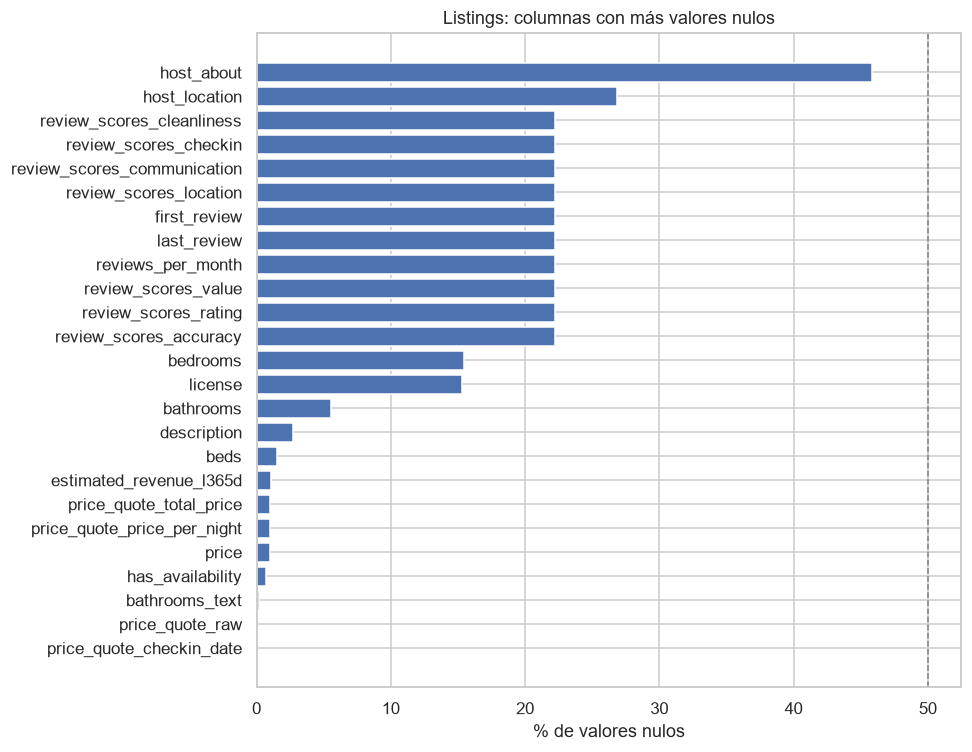

In [15]:
top = nulos_listings.head(25)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index[::-1], top["%"][::-1], color="#4C72B0")
ax.axvline(50, ls="--", c="grey", lw=1)
ax.set_xlabel("% de valores nulos"); ax.set_title("Listings: columnas con más valores nulos")
guardar("01_nulos_listings")

In [16]:
print("Reviews:"); display(tabla_nulos(reviews))
print("Calendar:"); display(tabla_nulos(calendar))

Reviews:


,nulos,%
comments,1,0.00


Calendar:


,nulos,%


In [17]:
# ¿Los nulos de review_scores corresponden a alojamientos sin reseñas?
sin_reviews = pd.to_numeric(listings["number_of_reviews"], errors="coerce").fillna(0) == 0
nulo_score = listings["review_scores_rating"].isna()
print(f"Listings sin reseñas: {sin_reviews.sum():,}")
print(f"Nulos en review_scores_rating: {nulo_score.sum():,}  ->  {(nulo_score & sin_reviews).sum():,} de ellos no tienen reseñas")

Listings sin reseñas: 4,265
Nulos en review_scores_rating: 4,265  ->  4,265 de ellos no tienen reseñas


**Interpretación – nulos.**
- Hay columnas **totalmente vacías** o casi vacías (p. ej. `neighbourhood_group_cleansed`, `calendar_updated`,
  `license`): no aportan información y se descartan.
- Los nulos de `review_scores_*`, `first_review`, `last_review` y `reviews_per_month` **no son errores**:
  corresponden a alojamientos sin reseñas. Decisión: `reviews_per_month = 0` y las calificaciones se dejan
  nulas (imputarlas sesgaría el promedio), creando el indicador `tiene_reviews`.
- `bedrooms`, `beds` y `bathrooms` tienen nulos moderados: se imputan con la **mediana por `room_type`**.
- `price` tiene nulos (alojamientos sin precio publicado en la fecha del scraping): no se inventa un valor;
  se completa con el precio del calendario cuando existe y si no se categoriza como "Sin precio".
- Campos descriptivos del host (`host_about`, `host_response_time`...) → "Sin información".

### Registros duplicados

In [18]:
def duplicados(df, llave):
    sin_listas = df.drop(columns=[c for c in df.columns if df[c].map(lambda v: isinstance(v, (list, dict))).any()])
    return {"filas idénticas": int(sin_listas.duplicated().sum()),
            f"llave {llave} repetida": int(df.duplicated(subset=llave).sum())}

dup = pd.DataFrame({
    "Listings": duplicados(listings, ["id"]),
    "Reviews": duplicados(reviews, ["id"]),
    "Calendar": duplicados(calendar, ["listing_id", "date"]),
}).T
dup

,filas idénticas,llave ['id'] repetida,"llave ['listing_id', 'date'] repetida"
Listings,0.00,0.00,NaN
Reviews,0.00,0.00,NaN
Calendar,0.00,NaN,0.00


**Interpretación – duplicados.** La llave natural de cada colección es `id` (Listings y Reviews) y
`(listing_id, date)` (Calendar). Cualquier repetición de la llave (por ejemplo por una doble importación a
MongoDB) duplicaría conteos e ingresos estimados, por lo que **sí es necesario eliminarlos** en la
transformación (`drop_duplicates` conservando el último registro). Si el conteo es 0, el paso se mantiene
como control de calidad y queda registrado en el log.

### Valores atípicos: `price`, `minimum_nights`, `availability_365`

In [19]:
eda = listings[["room_type", "neighbourhood_cleansed"]].copy()
eda["price"] = Transformacion.limpiar_precio(listings["price"])
for c in ["minimum_nights", "availability_365", "accommodates", "number_of_reviews"]:
    eda[c] = pd.to_numeric(listings[c], errors="coerce")

def iqr(serie, log=False):
    s = np.log(serie[serie > 0]) if log else serie.dropna()
    q1, q3 = s.quantile([.25, .75]); li, ls = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    if log: li, ls = np.exp(li), np.exp(ls)
    fuera = ((serie < li) | (serie > ls)).sum()
    return pd.Series({"límite inferior": li, "límite superior": ls, "outliers": fuera,
                      "% outliers": 100 * fuera / serie.notna().sum(), "máximo": serie.max()})

pd.DataFrame({"price (IQR sobre log)": iqr(eda["price"], log=True),
              "minimum_nights": iqr(eda["minimum_nights"]),
              "availability_365": iqr(eda["availability_365"])}).T

,límite inferior,límite superior,outliers,% outliers,máximo
price (IQR sobre log),"36,300.25","698,014.47",661.00,3.48,"448,176,567.00"
minimum_nights,-2.00,6.00,"4,053.00",21.13,32.00
availability_365,128.00,504.00,"1,129.00",5.88,365.00


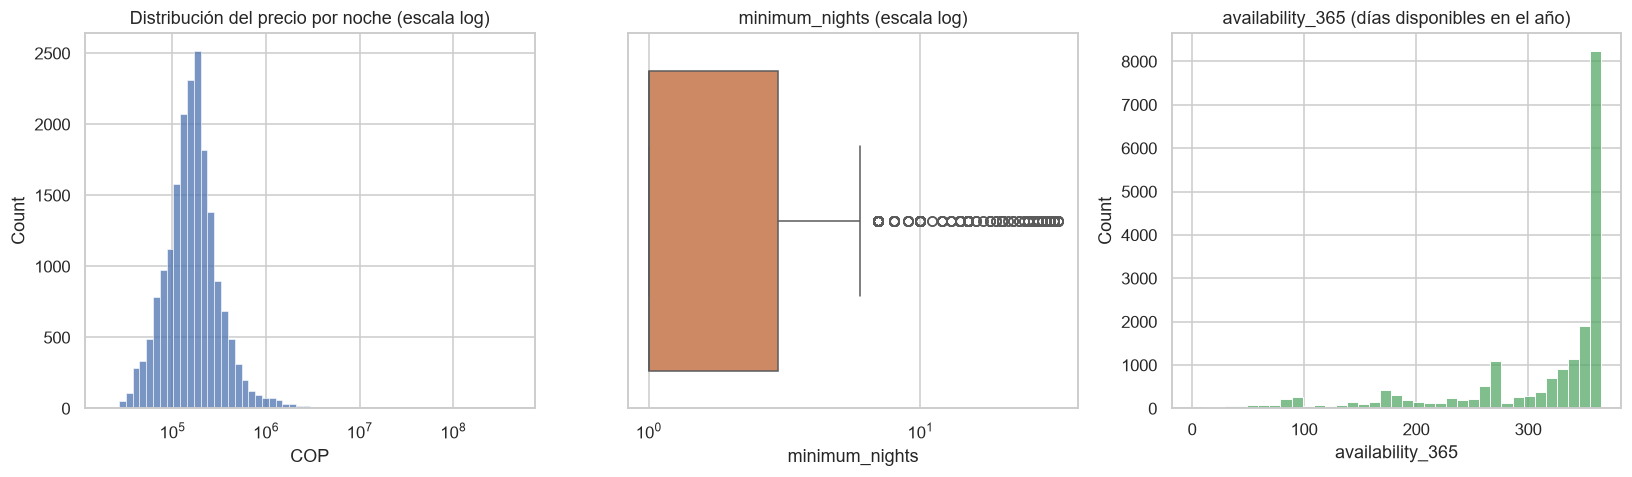

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.histplot(eda["price"].dropna(), bins=60, log_scale=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribución del precio por noche (escala log)"); axes[0].set_xlabel("COP")
sns.boxplot(x=eda["minimum_nights"], ax=axes[1], color="#DD8452"); axes[1].set_xscale("log")
axes[1].set_title("minimum_nights (escala log)")
sns.histplot(eda["availability_365"], bins=37, ax=axes[2], color="#55A868")
axes[2].set_title("availability_365 (días disponibles en el año)")
guardar("02_outliers_distribuciones")

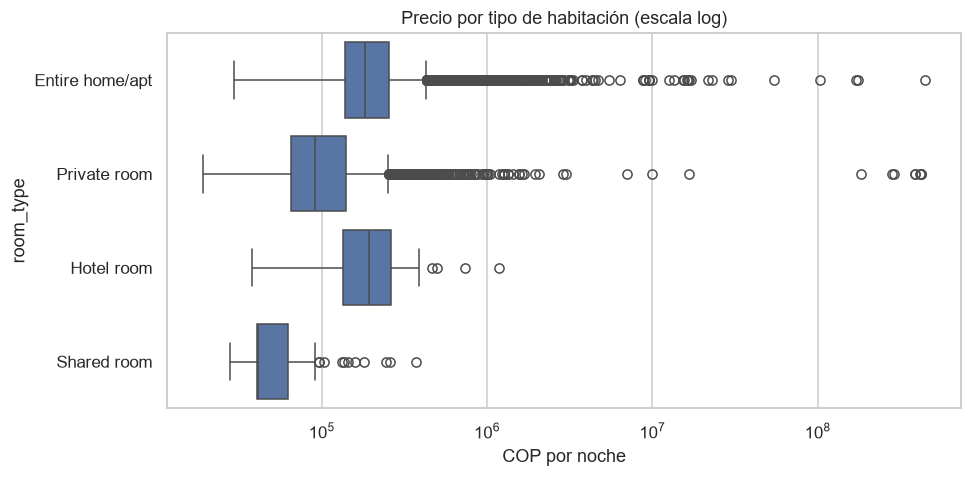

,count,25%,50%,75%,max
room_type,,,,,
Entire home/apt,"13,744.00","138,814.92","182,589.00","255,543.66","448,176,567.00"
Hotel room,33.00,"134,500.00","193,048.00","261,993.00","1,189,741.38"
Private room,"5,098.00","65,048.00","91,295.00","140,371.85","421,287,834.00"
Shared room,117.00,"40,500.00","41,453.00","62,810.38","369,800.00"


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=eda, x="price", y="room_type", ax=ax, showfliers=True)
ax.set_xscale("log"); ax.set_title("Precio por tipo de habitación (escala log)"); ax.set_xlabel("COP por noche")
guardar("03_precio_room_type")
eda.groupby("room_type")["price"].describe()[["count", "25%", "50%", "75%", "max"]]

In [22]:
p = eda["price"]
print(f"Mediana del precio: ${p.median():,.0f} COP  |  Media: ${p.mean():,.0f} COP  (la media está inflada por valores extremos)")
print(f"Precios >= 5.000.000 COP/noche: {(p >= 5_000_000).sum()}  |  Precio = 0: {(p == 0).sum()}")
print(f"minimum_nights > 365: {(eda['minimum_nights'] > 365).sum()}  |  >= 30 noches (estancia larga): {(eda['minimum_nights'] >= 30).mean():.1%}")
print(f"availability_365 = 0 (sin disponibilidad): {(eda['availability_365'] == 0).mean():.1%}  |  = 365: {(eda['availability_365'] == 365).mean():.1%}")

Mediana del precio: $161,460 COP  |  Media: $446,027 COP  (la media está inflada por valores extremos)
Precios >= 5.000.000 COP/noche: 38  |  Precio = 0: 0
minimum_nights > 365: 0  |  >= 30 noches (estancia larga): 17.3%
availability_365 = 0 (sin disponibilidad): 0.0%  |  = 365: 18.3%


**Interpretación – outliers.**
- **price** es fuertemente asimétrico a la derecha (media ≫ mediana), por eso el rango intercuartílico se
  calcula sobre `log(price)`. Existen precios extremos (millones de COP por noche) que suelen ser errores de
  digitación o tarifas "bloqueo". Decisión: **no se eliminan** (podrían ser reales, p. ej. casas grandes), se
  marcan con `outlier_precio = 1` para excluirlos de promedios cuando convenga; precios ≤ 0 pasan a nulo.
- **minimum_nights**: la mayoría está entre 1 y 3 noches, pero hay alojamientos con 30+ noches (renta mensual)
  y valores > 365 que no corresponden a alquiler turístico. Decisión: indicadores `estancia_larga` y
  `outlier_minimum_nights`; `maximum_nights` se recorta al tope de la plataforma (1.125).
- **availability_365** está acotado entre 0 y 365 (no hay valores imposibles), pero tiene concentraciones en
  0 (anuncios inactivos/bloqueados) y en 365 (calendario abierto sin reservas): son relevantes para el negocio
  y se conservan.

### Distribución geográfica y por tipo de alojamiento

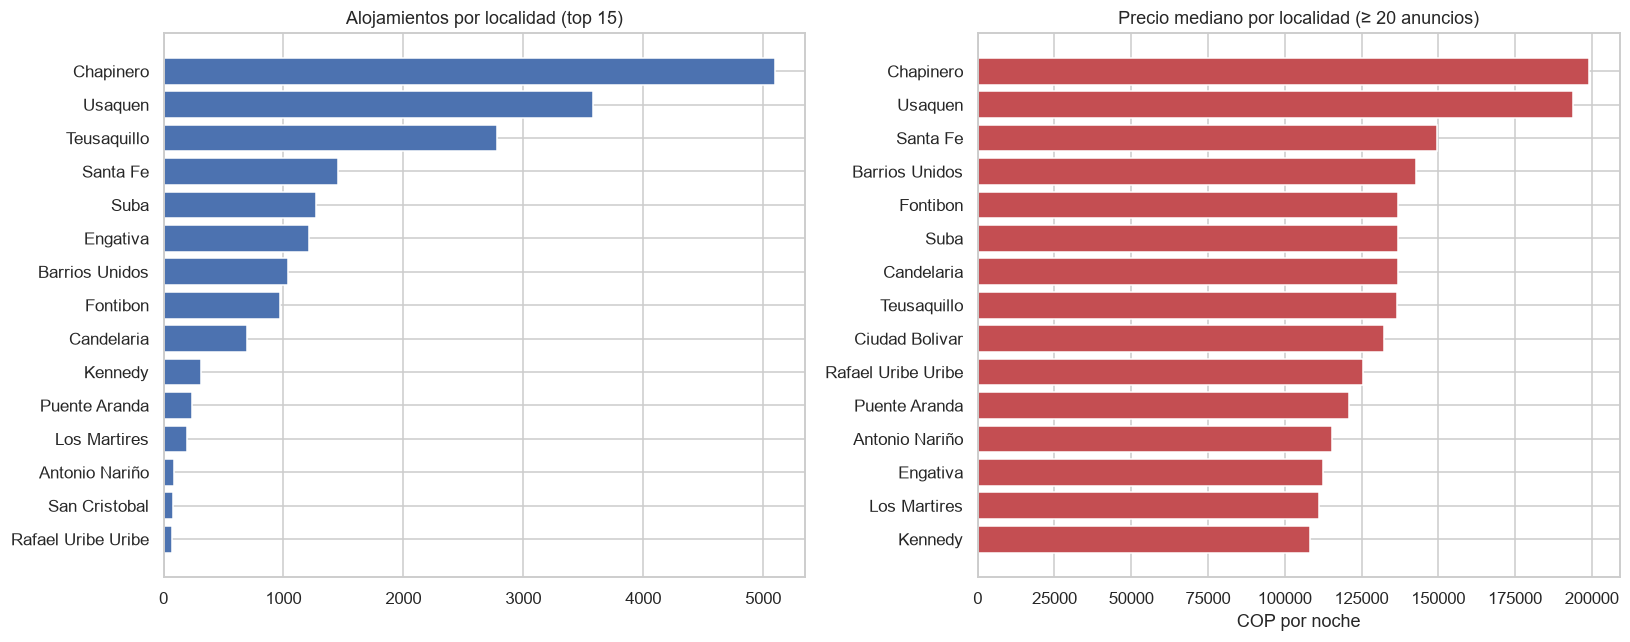

Las 3 localidades con más oferta concentran el 59.7% de los anuncios.


In [23]:
por_localidad = (eda.groupby("neighbourhood_cleansed")
                 .agg(alojamientos=("price", "size"), precio_mediano=("price", "median"))
                 .sort_values("alojamientos", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top = por_localidad.head(15)
axes[0].barh(top.index[::-1], top["alojamientos"][::-1], color="#4C72B0"); axes[0].set_title("Alojamientos por localidad (top 15)")
top2 = por_localidad[por_localidad["alojamientos"] >= 20].sort_values("precio_mediano", ascending=False).head(15)
axes[1].barh(top2.index[::-1], top2["precio_mediano"][::-1], color="#C44E52"); axes[1].set_title("Precio mediano por localidad (≥ 20 anuncios)")
axes[1].set_xlabel("COP por noche")
guardar("04_localidades")
print(f"Las 3 localidades con más oferta concentran el {por_localidad['alojamientos'].head(3).sum() / len(eda):.1%} de los anuncios.")

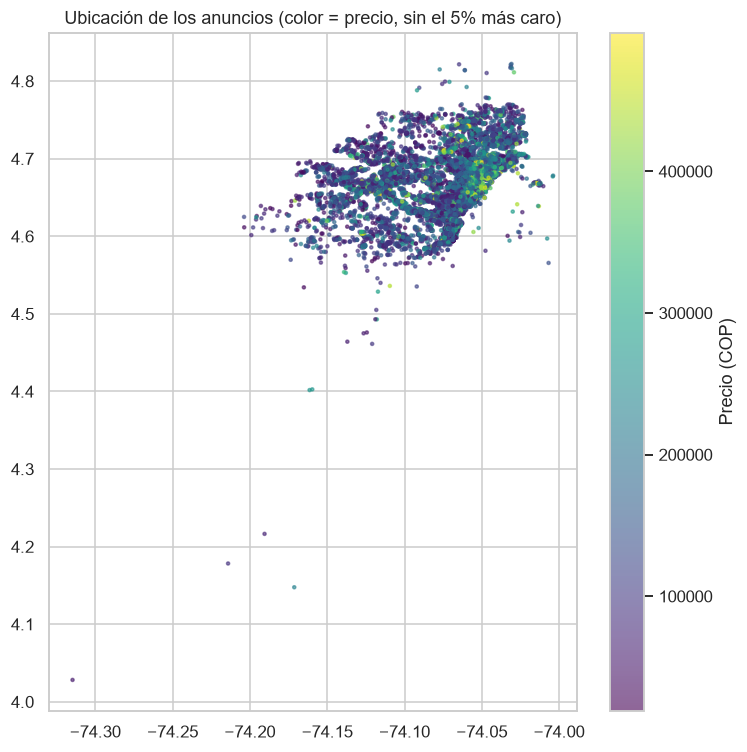

In [24]:
fig, ax = plt.subplots(figsize=(7, 7))
muestra = listings.assign(price=eda["price"]).dropna(subset=["price"])
muestra = muestra[muestra["price"] < eda["price"].quantile(.95)]
sc = ax.scatter(pd.to_numeric(muestra["longitude"]), pd.to_numeric(muestra["latitude"]), c=muestra["price"],
                cmap="viridis", s=4, alpha=.6)
plt.colorbar(sc, label="Precio (COP)"); ax.set_title("Ubicación de los anuncios (color = precio, sin el 5% más caro)")
guardar("05_mapa_precios")

### Correlaciones

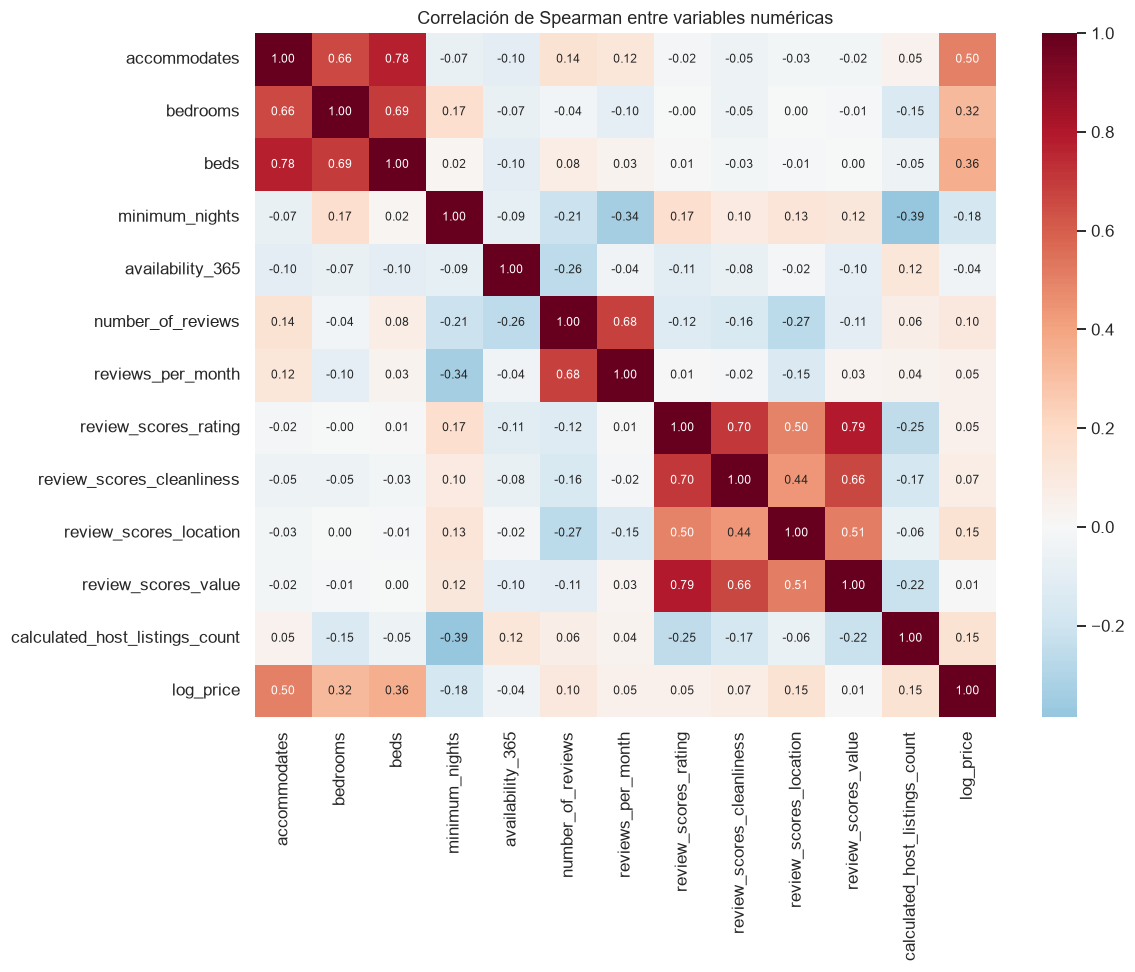

,corr. con log(price)
accommodates,0.50
beds,0.36
bedrooms,0.32
review_scores_location,0.15
calculated_host_listings_count,0.15
number_of_reviews,0.10
review_scores_cleanliness,0.07
review_scores_rating,0.05
reviews_per_month,0.05
review_scores_value,0.01


In [25]:
num = listings[["accommodates", "bedrooms", "beds", "minimum_nights", "availability_365", "number_of_reviews",
                "reviews_per_month", "review_scores_rating", "review_scores_cleanliness", "review_scores_location",
                "review_scores_value", "calculated_host_listings_count"]].apply(pd.to_numeric, errors="coerce")
num["log_price"] = np.log(eda["price"].where(eda["price"] > 0))
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlación de Spearman entre variables numéricas")
guardar("06_correlaciones")
corr["log_price"].drop("log_price").sort_values(ascending=False).to_frame("corr. con log(price)")

**Interpretación – correlaciones.** Se usa Spearman porque las variables son asimétricas y tienen outliers.
Es de esperar que el precio se asocie positivamente con la capacidad (`accommodates`, `bedrooms`, `beds`),
y que las calificaciones (`review_scores_*`) estén muy correlacionadas entre sí (redundancia: para modelos
conviene usar solo `review_scores_rating`). `number_of_reviews` y `reviews_per_month` también están
correlacionadas (ambas miden actividad). Verifique en la tabla anterior los valores obtenidos.

### Comportamiento temporal: reseñas y disponibilidad

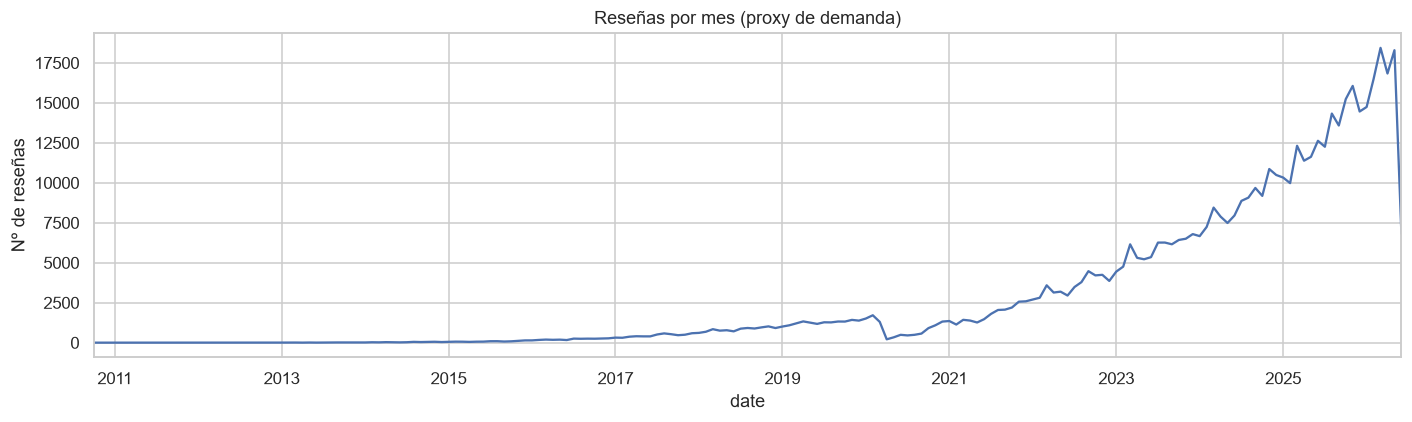

Meses con más reseñas: {'2026-03': 18438, '2026-05': 18290, '2026-04': 16834}


In [26]:
rev_mes = fechas_rev.dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(13, 4))
rev_mes.plot(ax=ax, color="#4C72B0"); ax.set_title("Reseñas por mes (proxy de demanda)"); ax.set_ylabel("Nº de reseñas")
guardar("07_reviews_por_mes")
print("Meses con más reseñas:", {str(k): v for k, v in rev_mes.sort_values(ascending=False).head(3).items()})

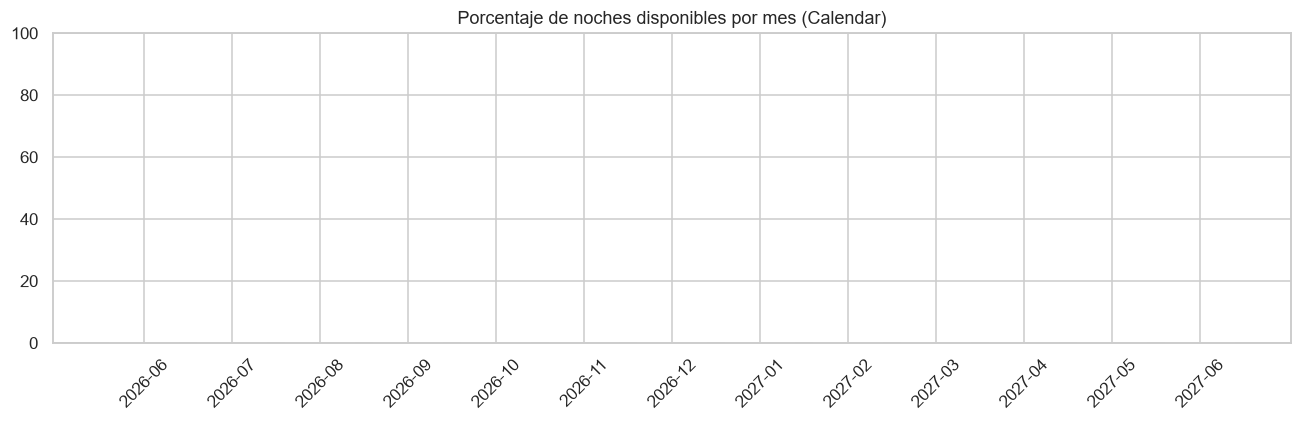

,mes,dias,disponibles,% disponible
0,2026-06,174141,0,0.00
1,2026-07,594797,0,0.00
2,2026-08,594797,0,0.00
3,2026-09,575610,0,0.00
4,2026-10,594797,0,0.00
5,2026-11,575610,0,0.00
6,2026-12,594797,0,0.00
7,2027-01,594797,0,0.00
8,2027-02,537236,0,0.00
9,2027-03,594797,0,0.00


In [27]:
# Disponibilidad mensual calculada DENTRO de MongoDB sobre toda la colección Calendar
pipeline = [
    {"$group": {"_id": {"$substr": ["$date", 0, 7]},
                "dias": {"$sum": 1},
                "disponibles": {"$sum": {"$cond": [{"$eq": ["$available", "t"]}, 1, 0]}}}},
    {"$sort": {"_id": 1}},
]
disp_mes = pd.DataFrame(list(ext.db["Calendar"].aggregate(pipeline, allowDiskUse=True))).rename(columns={"_id": "mes"})
disp_mes["% disponible"] = 100 * disp_mes["disponibles"] / disp_mes["dias"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(disp_mes["mes"], disp_mes["% disponible"], color="#55A868"); ax.set_ylim(0, 100)
ax.set_title("Porcentaje de noches disponibles por mes (Calendar)"); ax.tick_params(axis="x", rotation=45)
guardar("08_disponibilidad_mensual")
disp_mes

**Interpretación – temporalidad.** Las reseñas muestran la evolución de la demanda (caída marcada en 2020 por
la pandemia y recuperación posterior, además de estacionalidad en temporadas de vacaciones). El calendario
cubre los próximos 12 meses desde la fecha del *scraping*: los meses cercanos suelen tener menor
disponibilidad (ya reservados) y los lejanos aparecen casi totalmente disponibles, por lo que la
"ocupación estimada" (1 − disponibilidad) solo es confiable para el corto plazo. Esto justifica **agrupar el
calendario por mes y por alojamiento** (`calendar_mensual`).

## 2.3 Posibles transformaciones

### a) Campos anidados: `amenities` e información del host

Ejemplo de amenities (texto con formato de lista JSON):
 ['Blender', 'Luggage dropoff allowed', 'Long term stays allowed', 'Children’s dinnerware', 'Drying rack for clothing', 'Free parking on premises', 'Challenger gas stove', 'Clothing storage', 'Toaster', 'Baking sheet', 'Hair dryer', 'Refrigerator', 'Iron', 'Outdoor furniture', 'Building staff', 'Indoor fireplace: wood-burning', 'Microwave', 'Dining table', 'Smoke alarm', 'Dishes and silverware', 'Shampoo', 'Freezer', 'Free washer – In unit', 'Essentials', 'Wine glasses', 'Elevator', 'Fire extinguisher', 'Hot water', 'Shower gel', 'Piano', 'Kitchen', 'Single level home', 'Self check-in', 'Dedicated workspace', 'Wifi', 'Hot water kettle', 'Safe', 'Coffee maker', 'Private patio or balcony', 'Room-darkening shades', 'Board games', 'Books and reading material', '43 inch HDTV with standard cable', 'Children’s books and toys', 'Ethernet connection', 'Cooking basics', 'Extra pillows and blankets', 'Oven', 'Hangers', 'Bed linens', 'Carbon 

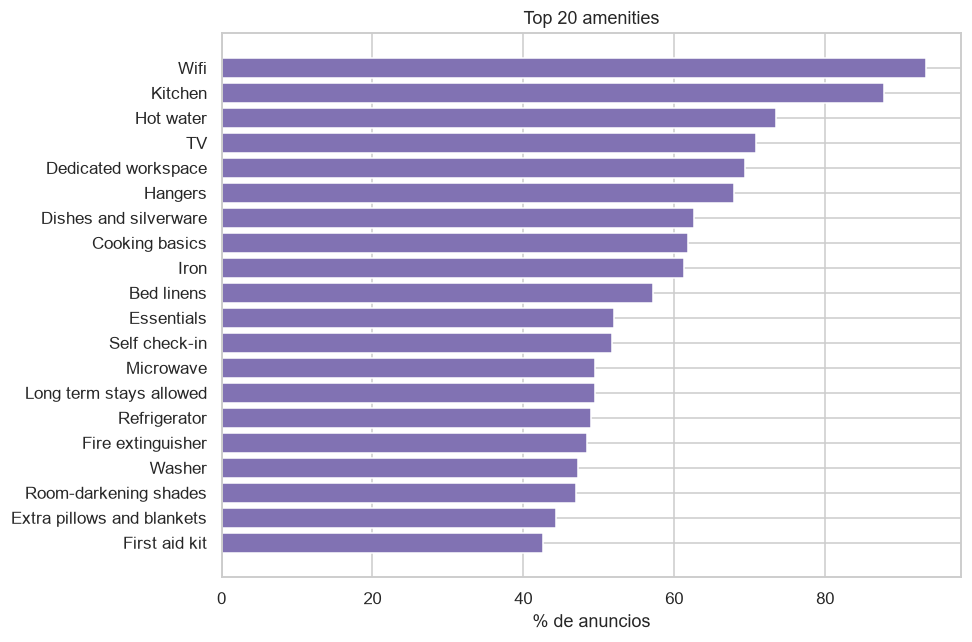

In [28]:
print("Ejemplo de amenities (texto con formato de lista JSON):\n", listings["amenities"].iloc[0][:300], "...")
amen = listings["amenities"].map(Transformacion.parsear_lista)
print(f"\nNº de amenities por anuncio: mediana = {amen.map(len).median():.0f}, máx = {amen.map(len).max()}")
conteo_amen = amen.explode().value_counts()
print(f"Amenities distintas: {len(conteo_amen):,}")
fig, ax = plt.subplots(figsize=(9, 6))
top = (conteo_amen.head(20) / len(listings) * 100)
ax.barh(top.index[::-1], top.values[::-1], color="#8172B3"); ax.set_xlabel("% de anuncios")
ax.set_title("Top 20 amenities")
guardar("09_top_amenities")

In [29]:
cols_host = [c for c in listings.columns if c.startswith("host_")]
print(f"Columnas del host repetidas en cada anuncio: {len(cols_host)} -> {cols_host}")
print(f"Anuncios: {len(listings):,} | Hosts únicos: {listings['host_id'].nunique():,}")
print(f"Hosts con más de 1 anuncio: {(listings.groupby('host_id').size() > 1).mean():.1%}")
print(f"Superhosts: {(listings.drop_duplicates('host_id')['host_is_superhost'] == 't').mean():.1%}")
listings[cols_host].head(3)

Columnas del host repetidas en cada anuncio: 13 -> ['host_id', 'host_url', 'host_profile_id', 'host_profile_url', 'host_name', 'host_location', 'host_about', 'host_is_superhost', 'host_picture_url', 'host_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified']
Anuncios: 19,187 | Hosts únicos: 8,335
Hosts con más de 1 anuncio: 28.5%
Superhosts: 0.0%


,host_id,host_url,host_profile_id,host_profile_url,host_name,host_location,host_about,host_is_superhost,host_picture_url,host_listings_count,host_verifications,host_has_profile_pic,host_identity_verified
0,113734,https://www.airbnb.com/users/show/113734,1462509905126026119,https://www.airbnb.com/users/profile/146250990...,Marcela,"Bogota, Colombia","I am an Architect and Urban Planner ,with my o...",True,https://a0.muscache.com/im/users/113734/profil...,3,None,True,True
1,321447,https://www.airbnb.com/users/show/321447,1462515641808590179,https://www.airbnb.com/users/profile/146251564...,Teresa,"Bogotá, Colombia",I'm a person that is always looking to enrich ...,True,https://a0.muscache.com/im/pictures/user/9bf8f...,24,None,True,True
2,676823,https://www.airbnb.com/users/show/676823,1462513470872353935,https://www.airbnb.com/users/profile/146251347...,Carlos,"Bogota, Colombia","Colombian who loves to travel, discover and me...",False,https://a0.muscache.com/im/pictures/user/f2663...,1,None,True,True


**Decisión.** `amenities` es una lista dentro de un texto: no se puede filtrar ni contar directamente.
Se **desanida** en (1) `n_amenities`, (2) variables binarias para las amenities clave (wifi, cocina, aire
acondicionado, parqueadero, lavadora, piscina, espacio de trabajo, TV) y (3) una tabla larga
`listing_amenities` (alojamiento–amenity). La información del host se repite en cada anuncio de un mismo
anfitrión: se separa en una **tabla dimensión `hosts`** (una fila por host), lo que elimina redundancia.

### b) Agrupación del calendario

In [30]:
cal = calendar.copy()
cal["mes"] = pd.to_datetime(cal["date"]).dt.to_period("M")
cal["disponible"] = (cal["available"] == "t").astype(int)
cal.groupby(["listing_id", "mes"])["disponible"].agg(["count", "mean"]).head(6)

count  mean
listing_id mes                 
1844341    2026-06      9  0.00
           2026-07     31  0.00
           2026-08     31  0.00
           2026-09     30  0.00
           2026-10     31  0.00
           2026-11     30  0.00

**Decisión.** El nivel diario es útil en SQLite, pero para análisis y para Excel (máx. 1.048.576 filas por hoja)
se genera `calendar_mensual` con días, días disponibles, tasa de disponibilidad, ocupación estimada y precio
promedio por alojamiento y mes. Se derivan además `anio`, `mes`, `dia`, `trimestre`, `dia_semana` y
`es_fin_de_semana` a partir de `date`.

### c) Estandarización de formatos (fecha, moneda, texto)

In [31]:
ejemplos = pd.DataFrame({
    "price (moneda)": listings["price"].dropna().head(3).values,
    "host_response_rate (%)": listings["host_response_rate"].dropna().head(3).values,
    "host_is_superhost (t/f)": listings["host_is_superhost"].dropna().head(3).values,
    "host_since (fecha texto)": listings["host_since"].dropna().head(3).values,
})
display(ejemplos)
pct_html = reviews["comments"].astype(str).str.contains(r"<br|\s{2,}", regex=True).mean()
print(f"Comentarios con HTML o espacios repetidos: {pct_html:.1%}")
print("Ejemplo de precio normalizado:", listings["price"].dropna().iloc[0], "->", Transformacion.limpiar_precio(listings["price"].dropna().head(1)).iloc[0])

KeyError: 'host_response_rate'

**Decisiones de formato:**
| Campo | Problema | Transformación |
|---|---|---|
| `price`, `adjusted_price` | Texto con `$` y `,` | Quitar símbolos → `float` (COP) |
| `date`, `host_since`, `first_review`, `last_review` | Texto | `datetime` → `YYYY-MM-DD` |
| `host_response_rate`, `host_acceptance_rate` | Texto `"95%"` | Proporción `0.95` |
| `available`, `instant_bookable`, `host_is_superhost` | `t`/`f` | 1/0 |
| `bathrooms_text` | `"1.5 shared baths"` | Nº de baños + indicador `bano_compartido` |
| `comments`, `name` | HTML (`<br/>`), espacios dobles | Quitar etiquetas y normalizar espacios |
| `neighbourhood_cleansed` | Nombre técnico | Renombrar a `localidad`, formato título |

## 2.4 Documentación de hallazgos

In [ ]:
precio = eda["price"]
hallazgos = {
    "Anuncios (listings)": f"{len(listings):,}",
    "Hosts únicos": f"{listings['host_id'].nunique():,}",
    "Reseñas": f"{len(reviews):,}",
    "Registros de calendario": f"{total_calendar:,}",
    "Columnas de listings con >50 % de nulos": int((listings.isna().mean() > .5).sum()),
    "Anuncios sin precio": f"{precio.isna().mean():.1%}",
    "Precio mediano (COP/noche)": f"${precio.median():,.0f}",
    "Tipo de alojamiento predominante": f"{listings['room_type'].mode()[0]} ({(listings['room_type'] == listings['room_type'].mode()[0]).mean():.1%})",
    "Localidad con más anuncios": por_localidad.index[0],
    "Anuncios sin reseñas": f"{sin_reviews.mean():.1%}",
    "Duplicados por llave (L / R / C)": f"{dup.iloc[0, 1]} / {dup.iloc[1, 1]} / {dup.iloc[2, 1]}",
    "Precio vacío en calendar": f"{calendar['price'].isna().mean():.1%}",
}
pd.Series(hallazgos, name="valor").to_frame()

### Principales hallazgos
1. **Inconsistencias de formato:** precios como texto con símbolos, porcentajes como texto, booleanos `t`/`f`,
   fechas como texto y comentarios con HTML. Todas se corrigen en `Transformacion`.
2. **Variables problemáticas:** columnas vacías (`neighbourhood_group_cleansed`, `calendar_updated`), `license`
   casi vacía, URLs y textos largos sin valor analítico; `price` con nulos y valores extremos;
   `maximum_nights` con valores centinela gigantes; precio del calendario frecuentemente vacío.
3. **Nulos estructurales:** las calificaciones faltan porque el anuncio no tiene reseñas (no es un error).
4. **Outliers:** el precio es muy asimétrico (se analiza en escala logarítmica); `minimum_nights` tiene un grupo
   de rentas mensuales y valores > 365.
5. **Correlaciones:** el precio se asocia a la capacidad del alojamiento; las calificaciones son redundantes
   entre sí.
6. **Concentración geográfica:** pocas localidades (típicamente Chapinero, Usaquén y Teusaquillo) concentran
   la mayor parte de la oferta y los precios más altos.

### Decisiones que impactan la fase de transformación
| # | Decisión | Justificación |
|---|---|---|
| 1 | Eliminar duplicados por llave natural | Evitar doble conteo |
| 2 | Conservar solo columnas analíticas | Reducir ruido y tamaño |
| 3 | Normalizar `price` y precios ≤ 0 → nulo | Permitir cálculos numéricos |
| 4 | Imputar `bedrooms`/`beds`/`bathrooms` con mediana por `room_type` | Nulos moderados; la mediana es robusta |
| 5 | No imputar `review_scores_*`; `reviews_per_month` = 0 | Son nulos estructurales |
| 6 | Marcar (no borrar) outliers de precio y noches | No perder información real |
| 7 | Categorizar precio en rangos (Económico … Lujo) | Facilitar el análisis de negocio |
| 8 | Desanidar `amenities` y separar `hosts` | Datos anidados/redundantes |
| 9 | Fechas a `YYYY-MM-DD` + año, mes, día, trimestre | Análisis temporal |
| 10 | Agrupar calendario por mes y completar su precio con el del listing | Tamaño y precio vacío |
| 11 | Integridad referencial (`listing_id` debe existir en listings) | Consistencia en SQLite |

In [ ]:
ext.cerrar()